# 7. Tujuan 3: faktor yang memengaruhi PM2.5

Korelasi cuaca per stasiun, perbandingan antarstasiun untuk lalu lintas dan jarak ke jalan, uji Kruskal-Wallis antarkategori lokasi, pengaruh arah dan kecepatan angin, serta model Gradient Boosting dengan permutation importance per kelompok faktor (musim, lokasi, cuaca, jam dan hari).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

In [3]:
MART = "../data/mart/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
SEKTOR = ["U", "TL", "T", "TG", "S", "BD", "B", "BL"]
MET = {"temperature_c": "Suhu", "humidity_pct": "Kelembapan", "wind_speed_ms": "Kecepatan angin"}
WARNA_KAT = {"Industri": "#6d4c41", "Gambut": "#c62828", "Perkotaan": "#1565c0",
             "Tepi Jalan": "#f9a825", "Latar Bersih": "#2e7d32"}

In [4]:
dim = pd.read_csv(MART + "dim_lokasi.csv")
info = dim[["stasiun", "pulau", "kategori_lokasi", "wilayah_gambut", "traffic_intensity_per_h",
            "distance_to_road_m", "baseline_pm25"]]
jam = pd.read_csv(MART + "fakta_udara_per_jam.csv",
                  usecols=["stasiun", "datetime", "pm25", "pm10", "no2", "co", "temperature_c", "humidity_pct",
                           "wind_speed_ms", "wind_direction_deg", "jam", "bulan", "akhir_pekan", "musim"])
jam = jam.merge(info, on="stasiun")
harian = pd.read_csv(MART + "fakta_udara_harian.csv")
harian = harian[harian["hari_valid"]].merge(info, on="stasiun")

In [5]:
kor = []
for st, g in jam.groupby("stasiun"):
    for musim_, gg in [("Semua", g), ("Hujan (Nov-Apr)", g[g["musim"] == "Hujan (Nov-Apr)"]),
                       ("Kemarau (Mei-Okt)", g[g["musim"] == "Kemarau (Mei-Okt)"])]:
        baris = {"stasiun": st, "musim": musim_}
        for c, nama in MET.items():
            x = gg[["pm25", c]].dropna()
            rho, p = spearmanr(x["pm25"], x[c]) if len(x) > 100 else (np.nan, np.nan)
            baris[f"rho_{c}"] = round(rho, 3)
            baris[f"p_{c}"] = p
        kor.append(baris)
kor = pd.DataFrame(kor).merge(info[["stasiun", "kategori_lokasi", "wilayah_gambut"]], on="stasiun")
kor_semua = kor[kor["musim"] == "Semua"]
kor_kat = kor_semua.groupby("kategori_lokasi")[[f"rho_{c}" for c in MET]].median().round(3)

In [6]:
kor_harian = []
for st, g in harian.groupby("stasiun"):
    baris = {"stasiun": st}
    for c in MET:
        x = g[["pm25", c]].dropna()
        baris[f"rho_harian_{c}"] = round(spearmanr(x["pm25"], x[c])[0], 3)
    kor_harian.append(baris)
kor_harian = pd.DataFrame(kor_harian)

In [7]:
jam["sektor"] = pd.cut((jam["wind_direction_deg"] + 22.5) % 360, bins=np.arange(0, 361, 45),
                       labels=SEKTOR, include_lowest=True, right=False)
mawar = jam.dropna(subset=["pm25", "sektor"]).groupby(["stasiun", "sektor"], observed=True).agg(
    pm25_rata2=("pm25", "mean"), jam=("pm25", "size")).reset_index()
mawar["pct_jam"] = (mawar["jam"] / mawar.groupby("stasiun")["jam"].transform("sum") * 100).round(1)
mawar["pm25_rata2"] = mawar["pm25_rata2"].round(1)
mawar["cukup_data"] = mawar["jam"] >= 200
ring_mawar = mawar[mawar["cukup_data"]].groupby("stasiun").apply(lambda g: pd.Series({
    "sektor_tertinggi": g.loc[g["pm25_rata2"].idxmax(), "sektor"],
    "pm25_sektor_tertinggi": g["pm25_rata2"].max(),
    "sektor_terendah": g.loc[g["pm25_rata2"].idxmin(), "sektor"],
    "pm25_sektor_terendah": g["pm25_rata2"].min(),
    "rasio_tertinggi_terendah": round(g["pm25_rata2"].max() / g["pm25_rata2"].min(), 2),
    "arah_angin_dominan": g.loc[g["jam"].idxmax(), "sektor"],
}), include_groups=False).reset_index().merge(info[["stasiun", "kategori_lokasi"]], on="stasiun")
ring_mawar = ring_mawar.sort_values("rasio_tertinggi_terendah", ascending=False)

In [8]:
jam["kelas_angin"] = pd.cut(jam["wind_speed_ms"], [-0.01, 1, 2, 3, 5, 50], labels=["<1", "1–2", "2–3", "3–5", ">5"])
angin = jam.groupby(["kategori_lokasi", "kelas_angin"], observed=True)["pm25"].mean().unstack().round(1)
jam["kelas_rh"] = pd.cut(jam["humidity_pct"], [0, 60, 70, 80, 90, 100.1], labels=["<60", "60–70", "70–80", "80–90", ">90"])
rh = jam.groupby(["kategori_lokasi", "kelas_rh"], observed=True)["pm25"].mean().unstack().round(1)

st = harian[harian["musim"] == "Hujan (Nov-Apr)"].groupby("stasiun")["pm25"].median().rename("pm25_median_hujan").reset_index()
st = st.merge(harian.groupby("stasiun")["pm25"].mean().rename("pm25_rata2").reset_index(), on="stasiun")
st = st.merge(jam.groupby("stasiun")["no2"].mean().rename("no2_rata2").reset_index(), on="stasiun")
st = st.merge(info, on="stasiun")
lok = []
for f in ["traffic_intensity_per_h", "distance_to_road_m", "baseline_pm25"]:
    for y in ["pm25_median_hujan", "pm25_rata2", "no2_rata2"]:
        rho, p = spearmanr(st[f], st[y])
        lok.append({"faktor": f, "target": y, "rho_spearman": round(rho, 3), "p_value": round(p, 4), "n_stasiun": len(st)})
lok = pd.DataFrame(lok)
st_ng = st[~st["wilayah_gambut"]]
for f in ["traffic_intensity_per_h", "distance_to_road_m"]:
    rho, p = spearmanr(st_ng[f], st_ng["pm25_median_hujan"])
    lok.loc[len(lok)] = {"faktor": f, "target": "pm25_median_hujan (non-gambut)", "rho_spearman": round(rho, 3),
                         "p_value": round(p, 4), "n_stasiun": len(st_ng)}
kw = kruskal(*[g["pm25_median_hujan"] for _, g in st.groupby("kategori_lokasi")])
kat_st = st.groupby("kategori_lokasi")[["pm25_median_hujan", "pm25_rata2", "traffic_intensity_per_h", "distance_to_road_m"]].median().round(1)

In [9]:
d = jam.dropna(subset=["pm25", "temperature_c", "humidity_pct", "wind_speed_ms", "wind_direction_deg"]).copy()
d = d[d["stasiun"] != "MER-01"]
d["angin_sin"] = np.sin(np.radians(d["wind_direction_deg"]))
d["angin_cos"] = np.cos(np.radians(d["wind_direction_deg"]))
d["akhir_pekan"] = d["akhir_pekan"].astype(int)
d["wilayah_gambut"] = d["wilayah_gambut"].astype(int)
for k in WARNA_KAT:
    d["kat_" + k] = (d["kategori_lokasi"] == k).astype(int)
fitur = {
    "temperature_c": "Suhu", "humidity_pct": "Kelembapan", "wind_speed_ms": "Kecepatan angin",
    "angin_sin": "Arah angin", "angin_cos": "Arah angin",
    "jam": "Jam", "bulan": "Bulan (musim)", "akhir_pekan": "Akhir pekan",
    "traffic_intensity_per_h": "Intensitas lalu lintas", "distance_to_road_m": "Jarak ke jalan",
    "wilayah_gambut": "Tipe lokasi", **{"kat_" + k: "Tipe lokasi" for k in WARNA_KAT},
}
X_cols = list(fitur)
rng = np.random.default_rng(42)
idx = rng.permutation(len(d))
latih, uji = d.iloc[idx[:200000]], d.iloc[idx[200000:260000]]
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)
model.fit(latih[X_cols], np.log1p(latih["pm25"]))
pred = np.expm1(model.predict(uji[X_cols]))
r2 = r2_score(uji["pm25"], pred)
r2_log = r2_score(np.log1p(uji["pm25"]), model.predict(uji[X_cols]))
pi = permutation_importance(model, uji[X_cols], np.log1p(uji["pm25"]), n_repeats=5, random_state=42, scoring="r2")
imp = pd.DataFrame({"fitur": X_cols, "kelompok": [fitur[c] for c in X_cols], "penurunan_r2": pi.importances_mean})
grup_kol = {}
for c in X_cols:
    grup_kol.setdefault(fitur[c], []).append(X_cols.index(c))
imp_grup = []
for nama, cols in grup_kol.items():
    turun = []
    for rep in range(5):
        Xp = uji[X_cols].copy()
        perm = np.random.default_rng(rep).permutation(len(Xp))
        for i in cols:
            Xp.iloc[:, i] = Xp.iloc[perm, i].values
        turun.append(r2_log - r2_score(np.log1p(uji["pm25"]), model.predict(Xp)))
    imp_grup.append({"faktor": nama, "penurunan_r2": np.mean(turun)})
imp_grup = pd.DataFrame(imp_grup).sort_values("penurunan_r2", ascending=False)
imp_grup["porsi_pct"] = (imp_grup["penurunan_r2"] / imp_grup["penurunan_r2"].sum() * 100).round(1)
imp_grup["penurunan_r2"] = imp_grup["penurunan_r2"].round(4)

In [10]:
hasil_sub = []
for nama, sub in [("Wilayah gambut", d[d["wilayah_gambut"] == 1]), ("Wilayah non-gambut", d[d["wilayah_gambut"] == 0])]:
    cols = [c for c in ["temperature_c", "humidity_pct", "wind_speed_ms", "angin_sin", "angin_cos", "jam", "bulan",
                        "akhir_pekan", "traffic_intensity_per_h", "distance_to_road_m"] + ["kat_" + k for k in WARNA_KAT]]
    s = sub.sample(min(120000, len(sub)), random_state=1)
    a, b = s.iloc[:90000], s.iloc[90000:]
    m = HistGradientBoostingRegressor(max_iter=300, random_state=42).fit(a[cols], np.log1p(a["pm25"]))
    base = r2_score(np.log1p(b["pm25"]), m.predict(b[cols]))
    for kel in sorted({fitur[c] for c in cols}):
        ii = [cols.index(c) for c in cols if fitur[c] == kel]
        turun = []
        for rep in range(3):
            Xp = b[cols].copy()
            perm = np.random.default_rng(rep).permutation(len(Xp))
            for i in ii:
                Xp.iloc[:, i] = Xp.iloc[perm, i].values
            turun.append(base - r2_score(np.log1p(b["pm25"]), m.predict(Xp)))
        hasil_sub.append({"wilayah": nama, "r2_model": round(base, 3), "faktor": kel, "penurunan_r2": round(np.mean(turun), 4)})
hasil_sub = pd.DataFrame(hasil_sub)
hasil_sub["porsi_pct"] = (hasil_sub["penurunan_r2"].clip(lower=0) /
                          hasil_sub.groupby("wilayah")["penurunan_r2"].transform(lambda s: s.clip(lower=0).sum()) * 100).round(1)
hasil_sub = hasil_sub.sort_values(["wilayah", "penurunan_r2"], ascending=[True, False])

In [11]:
with pd.ExcelWriter(OUT + "06_T3_faktor_pengaruh.xlsx") as w:
    imp_grup.to_excel(w, sheet_name="kepentingan_faktor_model", index=False)
    hasil_sub.to_excel(w, sheet_name="kepentingan_gambut_vs_non", index=False)
    pd.DataFrame([{"r2_skala_log": round(r2_log, 3), "r2_skala_asli": round(r2, 3), "n_latih": len(latih), "n_uji": len(uji)}]).to_excel(w, sheet_name="kinerja_model", index=False)
    kor_semua.to_excel(w, sheet_name="korelasi_cuaca_per_jam", index=False)
    kor.to_excel(w, sheet_name="korelasi_cuaca_per_musim", index=False)
    kor_kat.to_excel(w, sheet_name="korelasi_per_kategori")
    kor_harian.to_excel(w, sheet_name="korelasi_cuaca_harian", index=False)
    angin.to_excel(w, sheet_name="pm25_per_kelas_angin")
    rh.to_excel(w, sheet_name="pm25_per_kelas_kelembapan")
    ring_mawar.to_excel(w, sheet_name="arah_angin_ringkasan", index=False)
    mawar.to_excel(w, sheet_name="arah_angin_detail", index=False)
    lok.to_excel(w, sheet_name="faktor_lokasi_spearman", index=False)
    kat_st.to_excel(w, sheet_name="faktor_lokasi_per_kategori")
    st.round(1).to_excel(w, sheet_name="data_level_stasiun", index=False)
mawar.to_csv(MART + "fakta_arah_angin.csv", index=False)
kor_semua.merge(kor_harian, on="stasiun").to_csv(MART + "fakta_korelasi_cuaca.csv", index=False)
imp_grup.to_csv(MART + "fakta_kepentingan_faktor.csv", index=False)

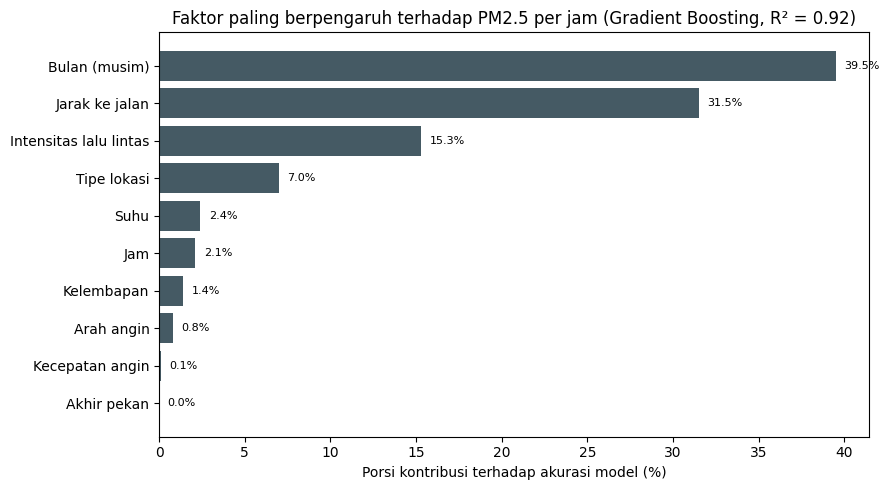

In [12]:
ig = imp_grup.sort_values("porsi_pct")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ig["faktor"], ig["porsi_pct"], color="#455a64")
for y, v in enumerate(ig["porsi_pct"]):
    ax.text(v + 0.5, y, f"{v}%", va="center", fontsize=8)
ax.set_xlabel("Porsi kontribusi terhadap akurasi model (%)")
ax.set_title(f"Faktor paling berpengaruh terhadap PM2.5 per jam (Gradient Boosting, R² = {r2_log:.2f})")
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_kepentingan_faktor.png", dpi=150)
plt.show()

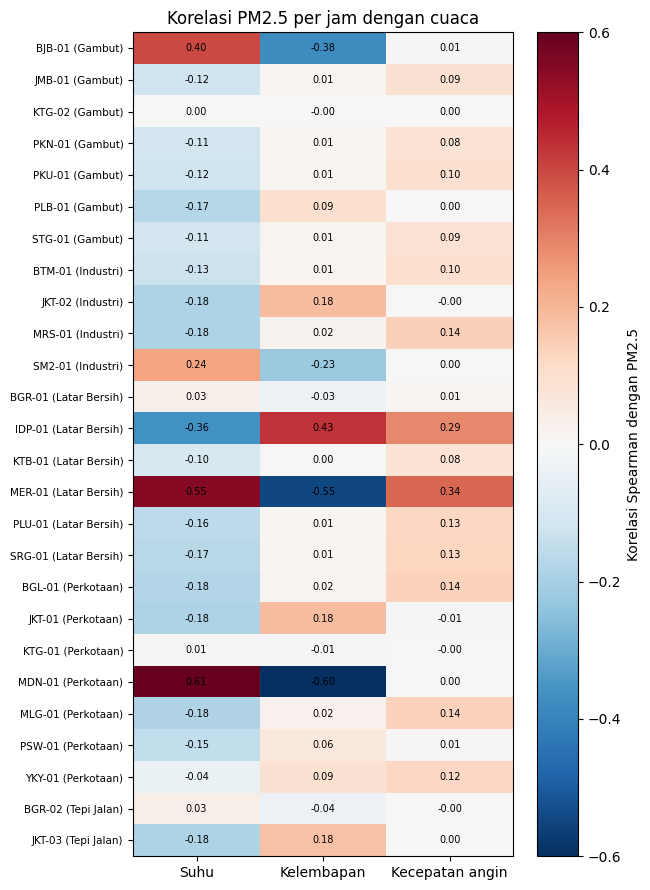

In [13]:
hm = kor_semua.set_index("stasiun")[[f"rho_{c}" for c in MET]]
hm.columns = list(MET.values())
hm = hm.loc[kor_semua.sort_values(["kategori_lokasi", "stasiun"])["stasiun"]]
fig, ax = plt.subplots(figsize=(6.5, 9))
im = ax.imshow(hm.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(3))
ax.set_xticklabels(hm.columns)
lbl = [f"{s} ({info.set_index('stasiun').loc[s, 'kategori_lokasi']})" for s in hm.index]
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(lbl, fontsize=7.5)
for i in range(hm.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="Korelasi Spearman dengan PM2.5")
ax.set_title("Korelasi PM2.5 per jam dengan cuaca")
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_korelasi_cuaca.png", dpi=150)
plt.show()

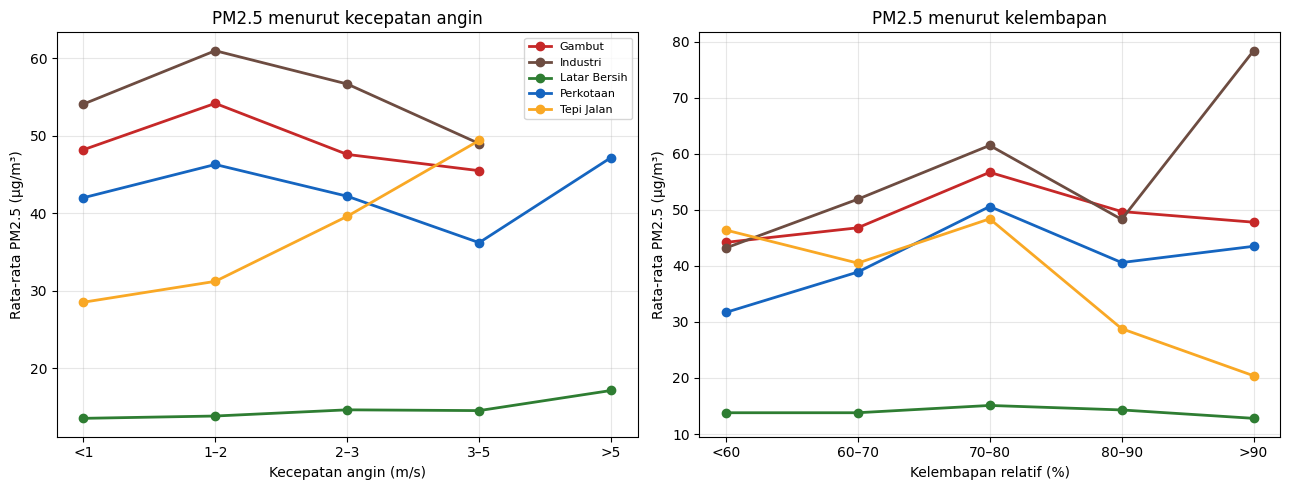

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, tab, judul, xl in [(axes[0], angin, "PM2.5 menurut kecepatan angin", "Kecepatan angin (m/s)"),
                           (axes[1], rh, "PM2.5 menurut kelembapan", "Kelembapan relatif (%)")]:
    for k, row in tab.iterrows():
        ax.plot(row.index.astype(str), row.values, marker="o", lw=2, color=WARNA_KAT[k], label=k)
    ax.set_title(judul)
    ax.set_xlabel(xl)
    ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_angin_kelembapan.png", dpi=150)
plt.show()

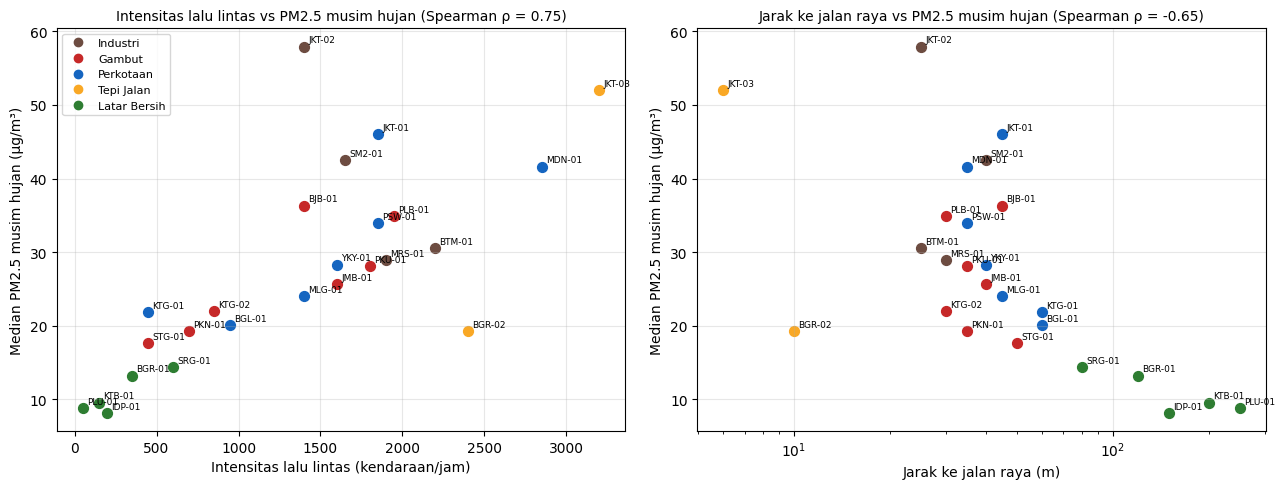

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f, xl in [(axes[0], "traffic_intensity_per_h", "Intensitas lalu lintas (kendaraan/jam)"),
                  (axes[1], "distance_to_road_m", "Jarak ke jalan raya (m)")]:
    for _, r in st.iterrows():
        ax.scatter(r[f], r["pm25_median_hujan"], color=WARNA_KAT[r["kategori_lokasi"]], s=50)
        ax.annotate(r["stasiun"], (r[f], r["pm25_median_hujan"]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
    rho = lok[(lok["faktor"] == f) & (lok["target"] == "pm25_median_hujan")]["rho_spearman"].iloc[0]
    ax.set_title(f"{xl.split(' (')[0]} vs PM2.5 musim hujan (Spearman ρ = {rho:.2f})", fontsize=10)
    ax.set_xlabel(xl)
    ax.set_ylabel("Median PM2.5 musim hujan (µg/m³)")
    if f == "distance_to_road_m":
        ax.set_xscale("log")
    ax.grid(alpha=0.3)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c) for c in WARNA_KAT.values()],
               labels=WARNA_KAT.keys(), fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_lalu_lintas_jarak.png", dpi=150)
plt.show()

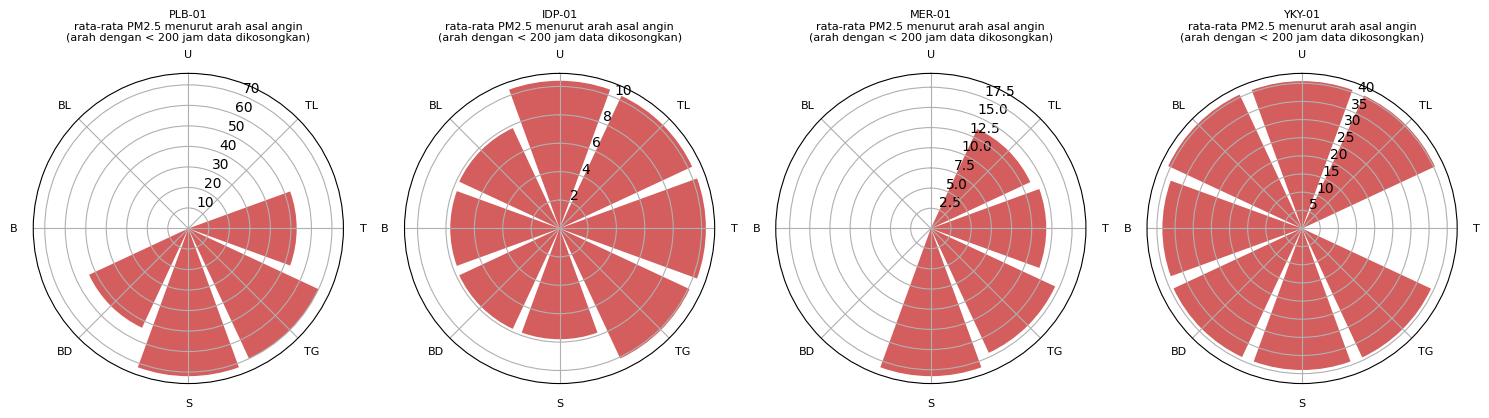

In [16]:
pilih = ring_mawar["stasiun"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), subplot_kw={"projection": "polar"})
for ax, s in zip(axes, pilih):
    m = mawar[(mawar["stasiun"] == s) & mawar["cukup_data"]].set_index("sektor").reindex(SEKTOR)
    sudut = np.radians(np.arange(0, 360, 45))
    ax.bar(sudut, m["pm25_rata2"].fillna(0).values, width=np.radians(40), color="#c62828", alpha=0.75)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(sudut)
    ax.set_xticklabels(SEKTOR, fontsize=8)
    ax.set_title(f"{s}\nrata-rata PM2.5 menurut arah asal angin\n(arah dengan < 200 jam data dikosongkan)", fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_mawar_polusi.png", dpi=150)
plt.show()

In [17]:
pd.set_option("display.width", 250)
print("R2 log", round(r2_log, 3), "R2 asli", round(r2, 3))
print(imp_grup.to_string())
print(hasil_sub.to_string())
print(kor_kat.to_string())
print(kor[kor["musim"] != "Semua"].groupby(["kategori_lokasi", "musim"])[[f"rho_{c}" for c in MET]].median().round(2).to_string())
print(kor_semua[["stasiun", "kategori_lokasi"] + [f"rho_{c}" for c in MET]].to_string())
print(kor_harian.to_string())
print(angin.to_string())
print(rh.to_string())
print(ring_mawar.to_string())
print(lok.to_string())
print("Kruskal kategori", kw)
print(kat_st.to_string())
print(st[["stasiun", "kategori_lokasi", "traffic_intensity_per_h", "distance_to_road_m", "pm25_median_hujan", "no2_rata2"]].sort_values("traffic_intensity_per_h").to_string())

R2 log 0.921 R2 asli 0.505
                   faktor  penurunan_r2  porsi_pct
5           Bulan (musim)        0.6612       39.5
8          Jarak ke jalan        0.5274       31.5
7  Intensitas lalu lintas        0.2565       15.3
9             Tipe lokasi        0.1177        7.0
0                    Suhu        0.0408        2.4
4                     Jam        0.0345        2.1
1              Kelembapan        0.0229        1.4
3              Arah angin        0.0133        0.8
2         Kecepatan angin        0.0015        0.1
6             Akhir pekan        0.0001        0.0
               wilayah  r2_model                  faktor  penurunan_r2  porsi_pct
2       Wilayah gambut     0.852           Bulan (musim)        1.4912       82.7
3       Wilayah gambut     0.852  Intensitas lalu lintas        0.2024       11.2
5       Wilayah gambut     0.852          Jarak ke jalan        0.0384        2.1
8       Wilayah gambut     0.852                    Suhu        0.0288        1.6
7 

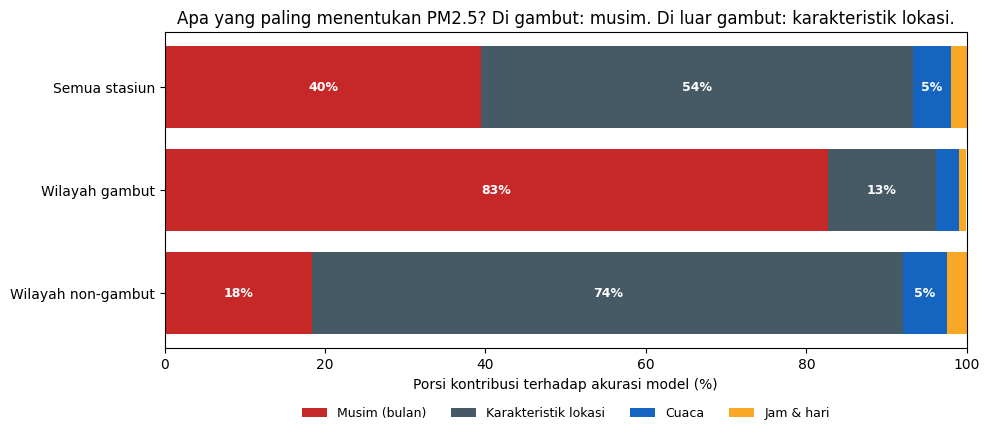

                      Semua stasiun  Wilayah gambut  Wilayah non-gambut
kelompok                                                               
Musim (bulan)                  39.5            82.7                18.4
Karakteristik lokasi           53.8            13.4                73.7
Cuaca                           4.7             2.9                 5.4
Jam & hari                      2.1             0.9                 2.5


In [18]:
KELOMPOK = {"Bulan (musim)": "Musim (bulan)", "Intensitas lalu lintas": "Karakteristik lokasi",
            "Jarak ke jalan": "Karakteristik lokasi", "Tipe lokasi": "Karakteristik lokasi",
            "Suhu": "Cuaca", "Kelembapan": "Cuaca", "Kecepatan angin": "Cuaca", "Arah angin": "Cuaca",
            "Jam": "Jam & hari", "Akhir pekan": "Jam & hari"}
URUT_K = ["Musim (bulan)", "Karakteristik lokasi", "Cuaca", "Jam & hari"]
WARNA_K = {"Musim (bulan)": "#c62828", "Karakteristik lokasi": "#455a64", "Cuaca": "#1565c0", "Jam & hari": "#f9a825"}
g_all = imp_grup.assign(kelompok=imp_grup["faktor"].map(KELOMPOK)).groupby("kelompok")["porsi_pct"].sum()
g_sub = hasil_sub.assign(kelompok=hasil_sub["faktor"].map(KELOMPOK)).groupby(["wilayah", "kelompok"])["porsi_pct"].sum().unstack()
ringkas = pd.concat([g_all.rename("Semua stasiun"), g_sub.T], axis=1)[["Semua stasiun", "Wilayah gambut", "Wilayah non-gambut"]].loc[URUT_K].round(1)
ringkas.to_csv(MART + "fakta_kepentingan_kelompok.csv")
with pd.ExcelWriter(OUT + "06_T3_faktor_pengaruh.xlsx", mode="a", engine="openpyxl") as w:
    ringkas.to_excel(w, sheet_name="ringkasan_kelompok_faktor")
fig, ax = plt.subplots(figsize=(10, 4.5))
kiri = np.zeros(3)
for k in URUT_K:
    vals = ringkas.loc[k].values
    ax.barh(ringkas.columns, vals, left=kiri, color=WARNA_K[k], label=k)
    for y, (l, v) in enumerate(zip(kiri, vals)):
        if v >= 4:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, weight="bold")
    kiri += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Porsi kontribusi terhadap akurasi model (%)")
ax.set_title("Apa yang paling menentukan PM2.5? Di gambut: musim. Di luar gambut: karakteristik lokasi.")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(GAMBAR + "06_T3_kelompok_faktor.png", dpi=150)
plt.show()
print(ringkas.to_string())